In [1]:
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [10, 8]
plt.rcParams['font.size'] = 18
import numpy as np
import pickle
import copy
import os

In [3]:
#from utils import plot_tradeoff

# Custom method for oxon fair since it 

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

import numpy as np
import matplotlib.pyplot as plt

def plot_interpolated_m1_m2(runs_m1, runs_m2, num_points=100):
    """
    Interpolates M2 values onto a common M1 grid to allow averaging.
    """
    # 1. Define a common M1 axis (the "X-axis" for your plot)
    # We find the global min/max overlapping range to avoid extrapolation errors
    all_m1 = np.concatenate(runs_m1)
    common_m1 = np.linspace(np.min(all_m1), np.max(all_m1), num_points)

    interp_m2_runs = []

    for m1, m2 in zip(runs_m1, runs_m2):
        # Sort by M1 so we can interpolate (M1 must be increasing for np.interp)
        # We need to sort m1 and m2 together!
        sorted_indices = np.argsort(m1)
        m1_sorted = np.array(m1)[sorted_indices]
        m2_sorted = np.array(m2)[sorted_indices]

        # Interpolate M2 onto the common M1 grid
        # left/right handles values outside the run's specific range
        m2_interp = np.interp(common_m1, m1_sorted, m2_sorted, left=np.nan, right=np.nan)
        interp_m2_runs.append(m2_interp)

    # 2. Convert to matrix
    m2_matrix = np.array(interp_m2_runs)

    # 3. Compute Mean and Std (ignoring NaNs at the very edges if ranges differ slightly)
    avg_m2 = np.nanmean(m2_matrix, axis=0)
    std_m2 = np.nanstd(m2_matrix, axis=0)

    # # 4. Plot
    # plt.figure(figsize=(10, 6))
    
    # # Plot Mean Line
    # plt.plot(common_m1, avg_m2, color='darkgreen', linewidth=2, label='Mean Metric 2')
    
    # # Plot Confidence Interval
    # plt.fill_between(common_m1, 
    #                  avg_m2 - std_m2, 
    #                  avg_m2 + std_m2, 
    #                  color='darkgreen', alpha=0.2, label='Standard Deviation')

    # # (Optional) Scatter the original points to verify fit
    # # for m1, m2 in zip(runs_m1, runs_m2):
    # #     plt.scatter(m1, m2, s=10, alpha=0.1, color='gray')

    # plt.xlabel('Metric 1')
    # plt.ylabel('Metric 2')
    # plt.title('Metric 1 vs Metric 2 (Interpolated Average)')
    # plt.legend()
    # plt.grid(True, alpha=0.3)
    # plt.show()

    return common_m1, avg_m2, std_m2

def average_parametric_2d(runs_m1, runs_m2, num_points=100):
    # Common parameter t from 0 to 1 (representing 0% to 100% progress along the curve)
    t_common = np.linspace(0, 1, num_points)

    m1_interp_list = []
    m2_interp_list = []

    for m1, m2 in zip(runs_m1, runs_m2):
        # 1. Sort pairs by m1 to ensure a consistent curve "direction"
        # (If your data is already a time-sequence, remove this sort)
        sorted_indices = np.argsort(m1)
        m1_sorted = np.array(m1)[sorted_indices]
        m2_sorted = np.array(m2)[sorted_indices]

        # 2. Define the t-axis for this specific run
        t_run = np.linspace(0, 1, len(m1))

        # 3. Interpolate both M1 and M2 onto the common t parameter
        m1_interp = np.interp(t_common, t_run, m1_sorted)
        m2_interp = np.interp(t_common, t_run, m2_sorted)

        m1_interp_list.append(m1_interp)
        m2_interp_list.append(m2_interp)

    # Convert to matrices
    M1_matrix = np.array(m1_interp_list)
    M2_matrix = np.array(m2_interp_list)

    # 4. Calculate Mean and Std for BOTH axes
    m1_mean = np.mean(M1_matrix, axis=0)
    m1_std = np.std(M1_matrix, axis=0)
    
    m2_mean = np.mean(M2_matrix, axis=0)
    m2_std = np.std(M2_matrix, axis=0)

    return m1_mean, m1_std, m2_mean, m2_std

def read_results(seeds, dataset, constraint, folder, lims=None):
    overall_bayes = []
    overall_unf = []

    overall_tradeoff = {}
    overall_mifpo = {}
    overall_exp = {}
    overall_fairret = {}
    overall_oxon = []

    for seed in seeds:
        file_name = f'{dataset}_{constraint}_{seed}.pickle'
        # Data was stored with pickle.dump
        with open(folder + file_name, 'rb') as f:
            results = pickle.load(f)
        # results = {
        #     'mifpo_pareto': mifpo_pareto,
        #     'exp_unfs': exp_unfs,
        #     'exp_errs': exp_errs,
        #     'exp_eps': exp_eps,
        #     'oxon_errs': oxon_errs,
        #     'oxon_unfs': oxon_unfs,
        #     'fairret_points': fairret_points,
        #     'est_tradeoff': est_tradeoff,
        #     'est_bayes': est_bayes,
        #     'est_unf': est_unf
        # }
        overall_bayes.append(results['est_bayes'])
        overall_unf.append(results['est_unf'])

        for key in results['est_tradeoff']:
            if key not in overall_tradeoff:
                overall_tradeoff[key] = []
            overall_tradeoff[key].append(results['est_tradeoff'][key])
        
        if results['mifpo_pareto'] is not None:
            for key in results['mifpo_pareto']:
                if key not in overall_mifpo:
                    overall_mifpo[key] = []
                overall_mifpo[key].append(results['mifpo_pareto'][key])
        else:
            overall_mifpo = None
        
        for i, val in enumerate(results['exp_eps']):
            if val not in overall_exp:
                overall_exp[val] = []
            overall_exp[val].append( (results['exp_unfs'][i], results['exp_errs'][i]) )
        
        for key in results['fairret_points']:
            if key not in overall_fairret:
                overall_fairret[key] = []
            overall_fairret[key].append(results['fairret_points'][key])
        
        overall_oxon.append( (results['oxon_unfs'], results['oxon_errs']) )
        
    # Averages
    bayes_err_mean = np.mean(overall_bayes)
    bayes_err_std = np.std(overall_bayes)
    unf_mean = np.mean(overall_unf)
    unf_std = np.std(overall_unf)

    # 0: err, 1: unf, 2: lambda
    for key in overall_tradeoff:
        temp_err_mean = np.mean([i[0] for i in overall_tradeoff[key]], axis=0)
        temp_err_std = np.std([i[0] for i in overall_tradeoff[key]], axis=0)
        temp_unf_mean = np.mean([i[1] for i in overall_tradeoff[key]], axis=0)
        temp_unf_std = np.std([i[1] for i in overall_tradeoff[key]], axis=0)
        overall_tradeoff[key] = ((temp_err_mean, temp_err_std), (temp_unf_mean, temp_unf_std))
    
    if overall_mifpo is not None:
        for key in overall_mifpo:
            temp_mean = np.mean(overall_mifpo[key], axis=0)
            temp_std = np.std(overall_mifpo[key], axis=0)
            overall_mifpo[key] = (temp_mean, temp_std)
    
    for key in overall_exp:
        temp_unf_mean = np.mean([i[0] for i in overall_exp[key]], axis=0)
        temp_unf_std = np.std([i[0] for i in overall_exp[key]], axis=0)
        temp_err_mean = np.mean([i[1] for i in overall_exp[key]], axis=0)
        temp_err_std = np.std([i[1] for i in overall_exp[key]], axis=0)
        overall_exp[key] = ((temp_err_mean, temp_err_std), (temp_unf_mean, temp_unf_std))
    
    # 0: err, 1: unf
    for key in overall_fairret:
        temp_err_mean = np.mean([i[0] for i in overall_fairret[key]], axis=0)
        temp_err_std = np.std([i[0] for i in overall_fairret[key]], axis=0)
        temp_unf_mean = np.mean([i[1] for i in overall_fairret[key]], axis=0)
        temp_unf_std = np.std([i[1] for i in overall_fairret[key]], axis=0)
        overall_fairret[key] = ((temp_err_mean, temp_err_std), (temp_unf_mean, temp_unf_std))
    
    # Zip sort each oxon array by unf
    for i in overall_oxon:
        temp_item = copy.deepcopy(i)
        zipped = list(zip(temp_item[0], temp_item[1]))
        zipped.sort(key=lambda x: x[0]) # sort by unf
        unfs, errs = zip(*zipped)
        i = (np.array(unfs), np.array(errs))
        # print min and max for both
        #print(min(i[0]), max(i[0]), min(i[1]), max(i[1]))
    
    oxon_unfs_all = [i[0] for i in overall_oxon]
    oxon_errs_all = [i[1] for i in overall_oxon]
    # Now interpolate and average
    #oxon_common_err, oxon_avg_unf, oxon_std_unf = plot_interpolated_m1_m2(oxon_errs_all, oxon_unfs_all, num_points=100)
    oxon_err_mean, oxon_err_std, oxon_unf_mean, oxon_unf_std = average_parametric_2d(oxon_errs_all, oxon_unfs_all, num_points=100)

    # Compare all 5 runs vs the two interpolated values (scatter plot) with error bars
    # plt.figure(figsize=(10, 6))
    # for i in range(len(oxon_unfs_all)):
    #     plt.scatter(oxon_errs_all[i], oxon_unfs_all[i], label=f'Run {i+1}')
    # plt.errorbar(oxon_common_err, oxon_avg_unf, yerr=oxon_std_unf, fmt='-o', color='red', label='Interpolated Mean')
    # plt.errorbar(oxon_err_mean, oxon_unf_mean, xerr=oxon_err_std, yerr=oxon_unf_std, fmt='-o', color='green', label='Parametric Mean')
    # plt.xlabel('Error Rate')
    # plt.ylabel('Unfairness')
    # plt.title('Oxon Fair: Error vs Unfairness Across Runs')
    # plt.legend() 

    # Error bar version of plot_tradeoff
    plt.figure(figsize=(10, 8))
    plt.axvline(x=bayes_err_mean, color='gray', linestyle='--')
    plt.axhline(y=unf_mean, color='gray', linestyle='--')
    #plt.errorbar(bayes_err_mean, unf_mean, xerr=bayes_err_std, yerr=unf_std, fmt='o', color='black', label='Bayes Optimal', capsize=5, capthick=3, elinewidth=3)
    # Estimated tradoff
    err_mean = []
    err_std = []
    unf_mean = []
    unf_std = []
    for key in overall_tradeoff:
        err_mean.append(overall_tradeoff[key][0][0])
        err_std.append(overall_tradeoff[key][0][1])
        unf_mean.append(overall_tradeoff[key][1][0])
        unf_std.append(overall_tradeoff[key][1][1])
    err_mean = np.array(err_mean)
    err_std = np.array(err_std)
    unf_mean = np.array(unf_mean)
    unf_std = np.array(unf_std)
    plt.errorbar(err_mean, unf_mean, xerr=err_std, yerr=unf_std, fmt='o', color='green', label='Estimated Trade-off',  capsize=5, capthick=3, elinewidth=3)
    # Exp grad
    exp_err_mean = []
    exp_err_std = []
    exp_unf_mean = []
    exp_unf_std = []
    for key in overall_exp:
        exp_err_mean.append(overall_exp[key][0][0])
        exp_err_std.append(overall_exp[key][0][1])
        exp_unf_mean.append(overall_exp[key][1][0])
        exp_unf_std.append(overall_exp[key][1][1])
    exp_err_mean = np.array(exp_err_mean)
    exp_err_std = np.array(exp_err_std)
    exp_unf_mean = np.array(exp_unf_mean)
    exp_unf_std = np.array(exp_unf_std)
    plt.errorbar(exp_err_mean, exp_unf_mean, xerr=exp_err_std, yerr=exp_unf_std, fmt='^', color='blue', label='Fairlearn Exp-Grad',  capsize=5, capthick=3, elinewidth=3)
    # MIFPO
    if overall_mifpo is not None:
        mifpo_err_mean = []
        mifpo_err_std = []
        mifpo_unf = []
        for key in overall_mifpo:
            mifpo_err_mean.append(overall_mifpo[key][0])
            mifpo_err_std.append(overall_mifpo[key][1])
            mifpo_unf.append(key)
        mifpo_err_mean = np.array(mifpo_err_mean)
        mifpo_err_std = np.array(mifpo_err_std)
        mifpo_unf = np.array(mifpo_unf)
        plt.errorbar(mifpo_err_mean, mifpo_unf, xerr=mifpo_err_std, fmt='s', color='red', label='MIFPO', alpha=0.3,  capsize=5, capthick=3, elinewidth=3)
    # FairRet
    fairret_err_mean = []
    fairret_err_std = []
    fairret_unf_mean = []
    fairret_unf_std = []
    for key in overall_fairret:
        fairret_err_mean.append(overall_fairret[key][0][0])
        fairret_err_std.append(overall_fairret[key][0][1])
        fairret_unf_mean.append(overall_fairret[key][1][0])
        fairret_unf_std.append(overall_fairret[key][1][1])
    fairret_err_mean = np.array(fairret_err_mean)
    fairret_err_std = np.array(fairret_err_std)
    fairret_unf_mean = np.array(fairret_unf_mean)
    fairret_unf_std = np.array(fairret_unf_std)
    plt.errorbar(fairret_err_mean, fairret_unf_mean, xerr=fairret_err_std, yerr=fairret_unf_std, fmt='*', color='purple', label='FairRet')
    # Oxon Fair
    plt.errorbar(oxon_err_mean, oxon_unf_mean, xerr=oxon_err_std, yerr=oxon_unf_std, fmt='D', color='orange', label='OxonFair', alpha=0.3,  capsize=5, capthick=3, elinewidth=3)
    plt.xlabel('Error Rate')
    plt.ylabel(f'Unfairness ({constraint})')
    # Ticks
    plt.xticks(rotation=30, ha='right')
    # grid
    plt.grid(True, alpha=0.3)
    if dataset == 'gaussian':
        name = 'Gaussian'
    elif dataset == 'adult':
        name = 'Adult'
    elif dataset == 'compas':
        name = 'COMPAS'
    elif dataset == 'cifar10h':
        name = 'CIFAR-10H'
    plt.title(f'Error vs Unfairness ({name}, {constraint})')
    # add limits
    # lims is array of arrays ((x_lims, ..), (ylims, ..)) or None
    if lims[0][0] is not None:
        plt.xlim(lims[0][0], lims[0][1])
        plt.ylim(lims[1][0], lims[1][1])
    plt.legend(loc='upper right')
    # Save
    if os.path.exists('./plots/') == False:
        os.makedirs('./plots/')
    plt.savefig(f'./plots/{dataset}_{constraint}_tradeoff.png', bbox_inches='tight')
    plt.show()

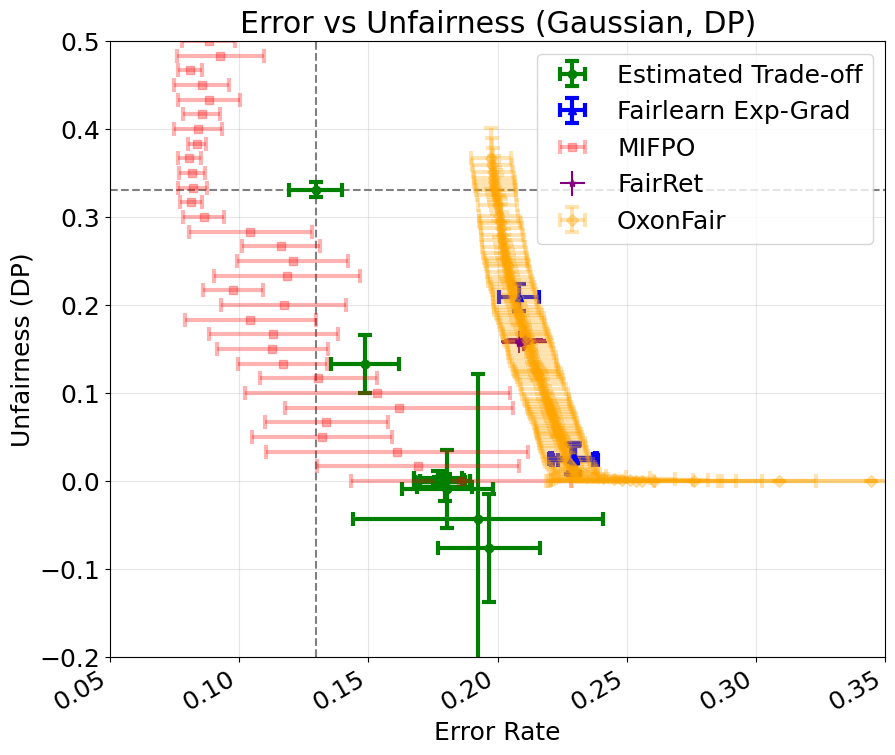

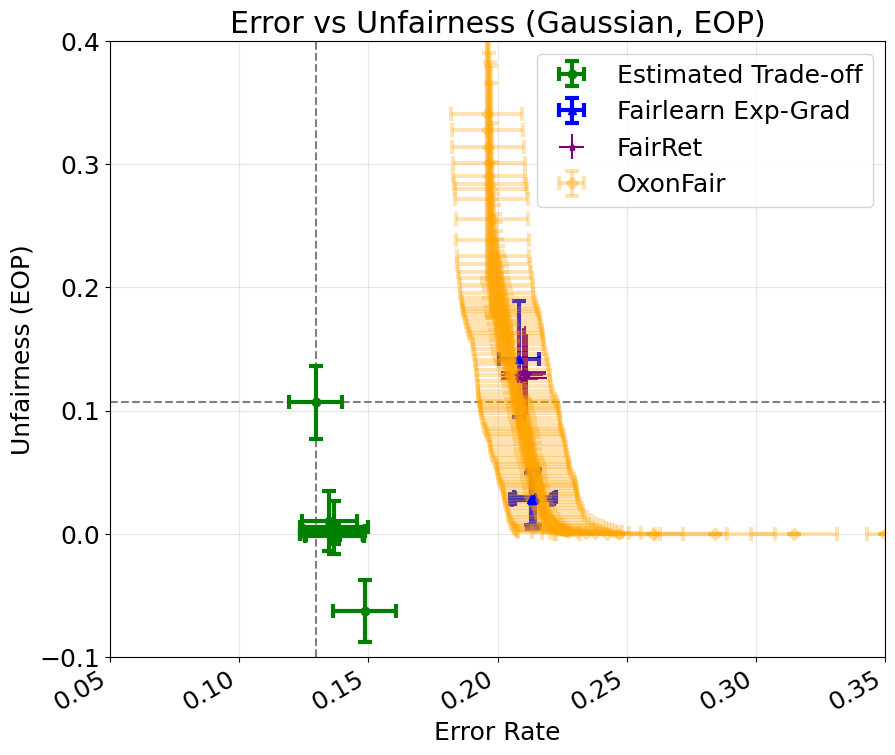

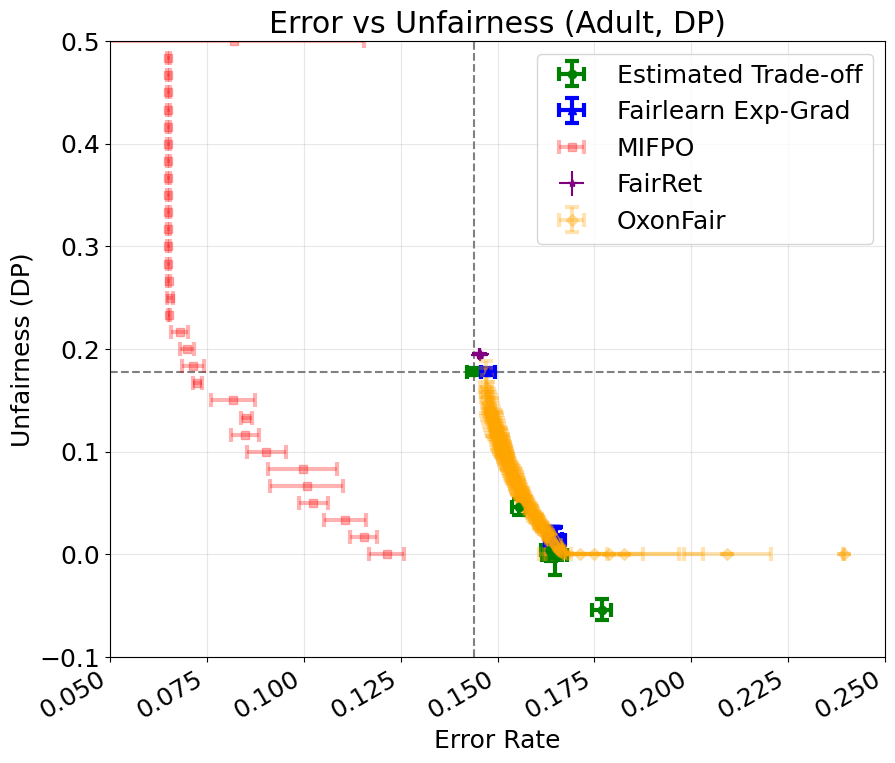

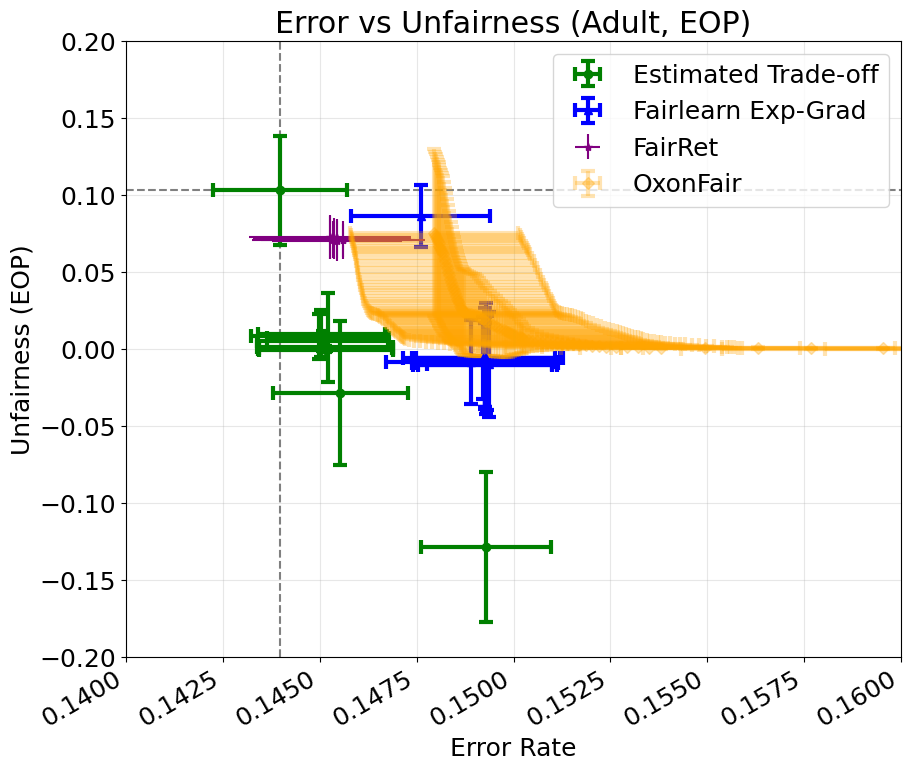

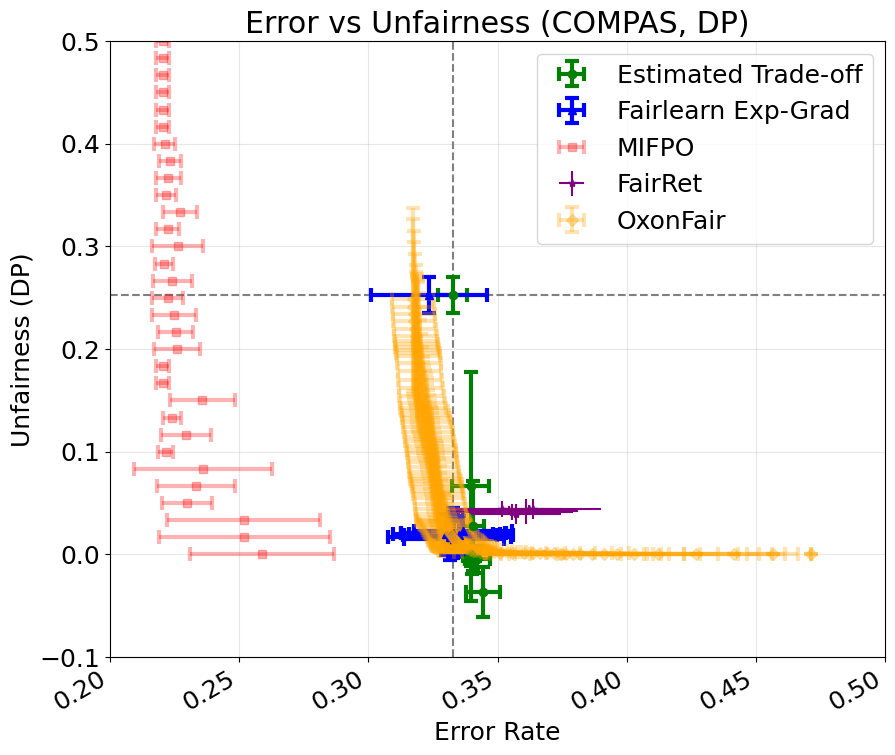

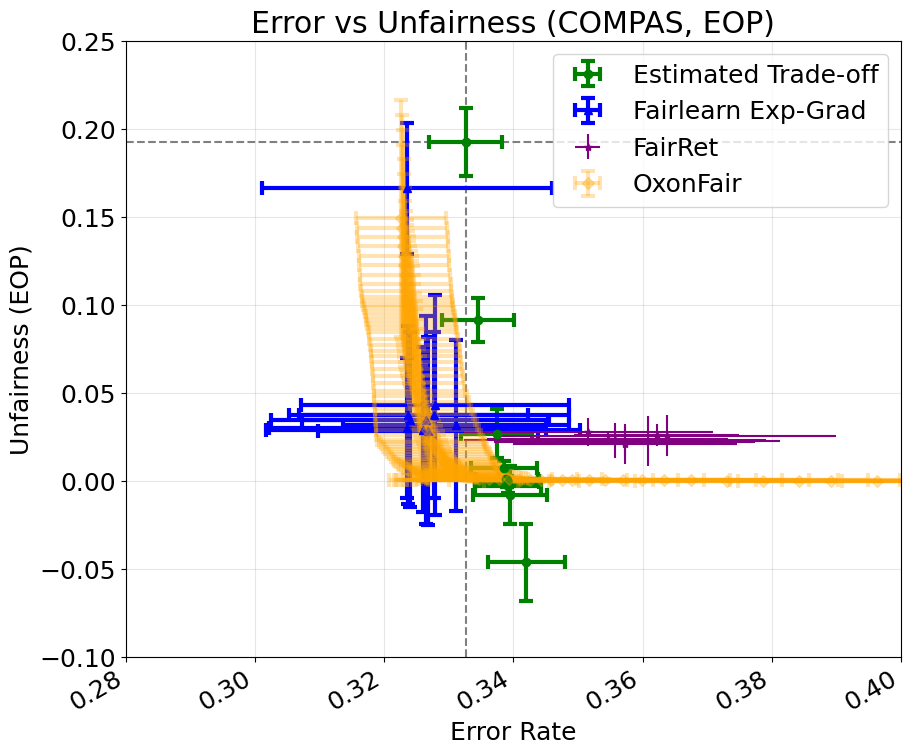

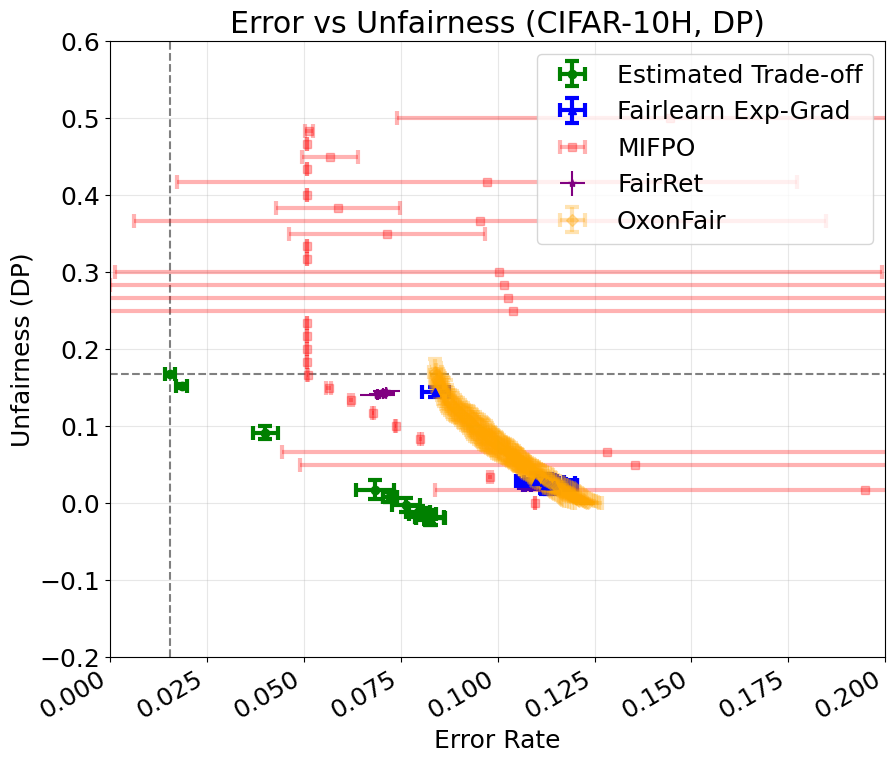

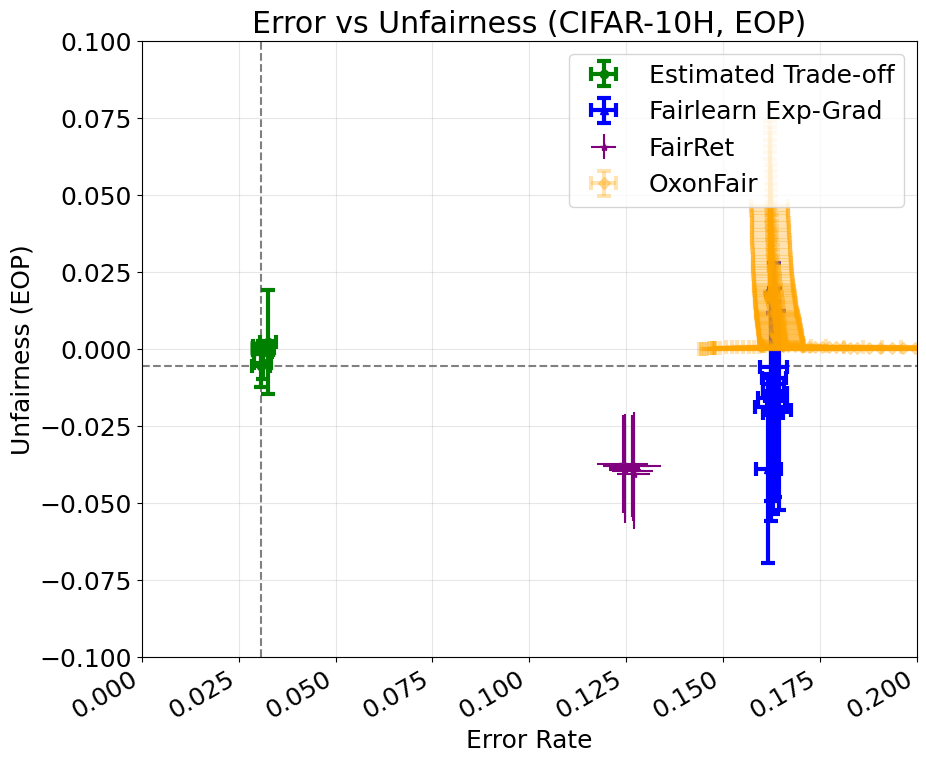

In [4]:
for d in ['gaussian', 'adult', 'compas', 'cifar10h']:
    for m in ['DP', 'EOP']:
        dataset = d
        metric = m
        folder = 'gaussian_dim_100/' if dataset == 'gaussian' else dataset + '/'
        seeds = [42, 100, 2021, 7, 1234]

        if dataset == 'gaussian' and metric == 'DP':
            y_lim = (-0.2, 0.5)
            x_lim = (0.05, 0.35)
        elif dataset == 'gaussian' and metric == 'EOP':
            y_lim = (-0.1, 0.4)
            x_lim = (0.05, 0.35)
        elif dataset == 'adult' and metric == 'DP':
            y_lim = (-0.1,0.5)
            x_lim = (0.05, 0.25)
        elif dataset == 'adult' and metric == 'EOP':
            y_lim = (-0.2, 0.2)
            x_lim = (0.14, 0.16)
        elif dataset == 'cifar10h' and metric == 'DP':
            y_lim = (-0.2, 0.6)
            x_lim = (0., 0.2)
        elif dataset == 'cifar10h' and metric == 'EOP':
            y_lim = (-0.1, 0.1)
            x_lim = (0., 0.2)
        elif dataset == 'compas' and metric == 'DP':
            y_lim = (-0.1, 0.5)
            x_lim = (0.2, 0.5)
        elif dataset == 'compas' and metric == 'EOP':
            y_lim = (-0.1, 0.25)
            x_lim = (0.28, 0.4)

        read_results(dataset=dataset, constraint=metric, folder=folder, seeds=seeds, lims=(x_lim, y_lim))

In [5]:
def plot_tradeoff(tradeoff, tradeoff_est, true_bayes, true_unf, predicted_points=None, lims=None):
    x = []
    y = []
    colors = []
    for key in tradeoff:
        #if key != -1:
        x.append(tradeoff[key][0])
        y.append(tradeoff[key][1])
        colors.append(tradeoff[key][2])
    x = np.array(x)
    y = np.array(y)
    plt.scatter(x, y, c=colors, cmap='viridis', label='True Trade-off', marker='o')
    # x_y_spline = interp1d(x, y, kind='cubic')
    # X_ = np.linspace(x.min(), x.max(), 500)
    # Y_ = x_y_spline(X_)
    # plt.plot(X_, Y_, color='blue', linestyle='--', label='True Trade-off (spline)')
    # Draw a vertical line at the bayes optimal point
    plt.axvline(x=true_bayes, color='black', linestyle='--')
    plt.axhline(y=true_unf, color='black', linestyle='--')
    plt.colorbar(label='Lambda')
    # x_est = []
    # y_est = []
    # colors_est = []
    # for key in tradeoff_est:
    #     #if key != -1:
    #     x_est.append(tradeoff_est[key][0])
    #     y_est.append(tradeoff_est[key][1])
    #     colors_est.append(tradeoff_est[key][2])
    # x_est = np.array(x_est)
    # y_est = np.array(y_est)
    # plt.scatter(x_est, y_est, c=colors_est, cmap='plasma', marker='x', label='Estimated Trade-off')
    # remove duplicates from x_est, y_est, colors_est
    # unique_indices = np.unique(x_est, return_index=True)[1]
    # u_x_est = x_est[unique_indices]
    # u_y_est = y_est[unique_indices]
    # u_colors_est = np.array(colors_est)[unique_indices]
    # x_y_spline_est = interp1d(u_x_est, u_y_est, kind='cubic')
    # X_est_ = np.linspace(x_est.min(), x_est.max(), 500)
    # Y_est_ = x_y_spline_est(X_est_)
    # plt.plot(X_est_, Y_est_, color='orange', linestyle='--', label='Estimated Trade-off (spline)')
    # plt.colorbar(label='Lambda (Estimated)')
    if predicted_points is not None:
        if 'exp_grad' in predicted_points:
            unfs, errs, eps = predicted_points['exp_grad']
            unfs = np.array(unfs)
            errs = np.array(errs)
            plt.scatter(errs, unfs, c='green', marker='^', label='Fairlearn Exp-Grad')
        if 'pareto' in predicted_points and predicted_points['pareto'] is not None:
            unfs_p, errs_p = list(predicted_points['pareto'].keys()), list(predicted_points['pareto'].values())
            unfs_p = np.array(unfs_p)
            errs_p = np.array(errs_p)
            plt.scatter(errs_p, unfs_p, c='red', marker='s', label='MIFPO')
        if 'fairret' in predicted_points:
            points_fairret = predicted_points['fairret']
            eps_fairret = []
            unfs_fairret = []
            errs_fairret = []
            for key in points_fairret:
                errs_fairret.append(points_fairret[key][0])
                unfs_fairret.append(points_fairret[key][1])
                eps_fairret.append(key)
            unfs_fairret = np.array(unfs_fairret)
            errs_fairret = np.array(errs_fairret)
            plt.scatter(errs_fairret, unfs_fairret, c='blue', marker='*', label='FairRet')
        if 'oxon' in predicted_points:
            unfs_oxon, errs_oxon = predicted_points['oxon']
            unfs_oxon = np.array(unfs_oxon)
            errs_oxon = np.array(errs_oxon)
            plt.scatter(errs_oxon, unfs_oxon, c='purple', marker='D', label='OxonFair')
        # Remove duplicates
        # unique_indices_exp = np.unique(errs, return_index=True)[1]
        # u_errs = errs[unique_indices_exp]
        # u_unfs = unfs[unique_indices_exp]
        # x_y_spline_exp = interp1d(u_errs, u_unfs, kind='cubic')
        # X_exp_ = np.linspace(errs.min(), errs.max(), 500)
        # Y_exp_ = x_y_spline_exp(X_exp_)
        # plt.plot(X_exp_, Y_exp_, color='green', linestyle='--', label='Fairlearn Exp-Grad (spline)')
        # unfs_fairret, errs_fairret, eps_fairret = predicted_points['fairret']
        # unfs_fairret = np.array(unfs_fairret)
        # errs_fairret = np.array(errs_fairret)
        # Remove duplicates
        # unique_indices_fairret = np.unique(errs_fairret, return_index=True)[1]
        # u_errs_fairret = errs_fairret[unique_indices_fairret]
        # u_unfs_fairret = unfs_fairret[unique_indices_fairret]
        # x_y_spline_fairret = interp1d(u_errs_fairret, u_unfs_fairret, kind='cubic')
        # X_fairret_ = np.linspace(errs_fairret.min(), errs_fairret.max(), 500)
        # Y_fairret_ = x_y_spline_fairret(X_fairret_)
        # plt.plot(X_fairret_, Y_fairret_, color='red', linestyle='--', label='FairRet (spline)')
        #plt.scatter(errs_fairret, unfs_fairret, c='red', marker='s', label='FairRet')
    plt.xlabel('Error')
    plt.ylabel('Unfairness')
    if lims is not None:
        plt.xlim(lims[0][0], lims[0][1])
        plt.ylim(lims[1][0], lims[1][1])
    plt.title('Trade-off Curve')
    plt.legend()

In [21]:
#from utils import plot_tradeoff
def read_results(seeds=['42'], dataset='gaussian', constraint='DP', output_dir='./output/'):
    seed = seeds[0]
    file_name = f'{dataset}_{constraint}_{seed}.pickle'
    # Data was stored with pickle.dump
    with open(f'{output_dir}'+ file_name, 'rb') as f:
        results = pickle.load(f)
    # results = {
    #     'mifpo_pareto': mifpo_pareto,
    #     'exp_unfs': exp_unfs,
    #     'exp_errs': exp_errs,
    #     'exp_eps': exp_eps,
    #     'oxon_errs': oxon_errs,
    #     'oxon_unfs': oxon_unfs,
    #     'fairret_points': fairret_points,
    #     'est_tradeoff': est_tradeoff,
    #     'est_bayes': est_bayes,
    #     'est_unf': est_unf
    # }
    plot_tradeoff(
        tradeoff=results['est_tradeoff'],
        tradeoff_est=None,
        predicted_points={
            'exp_grad': (results['exp_unfs'], results['exp_errs'], results['exp_eps']),
            'pareto': results['mifpo_pareto'],
            'fairret': results['fairret_points'],
            'oxon': (results['oxon_unfs'], results['oxon_errs']),
        },
        true_bayes=results['est_bayes'], # For gaussian, it will almost be the same, for others we cant compute the bayes error
        true_unf=results['est_unf'],
    )

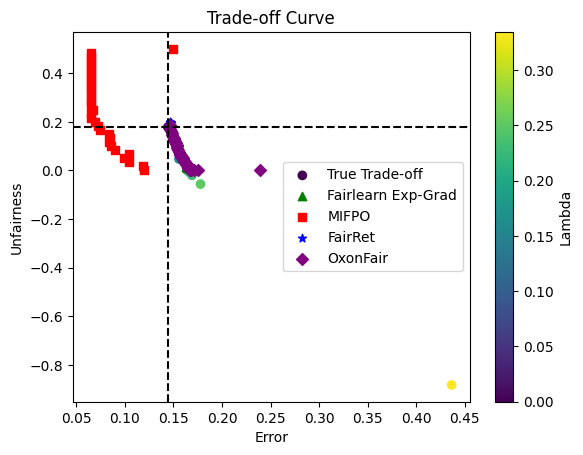

In [22]:
#read_results(constraint='DP', seeds=['100'])
#read_results(dataset='cifar10h', constraint='DP')
#read_results(dataset='adult', constraint='EOP')

dataset = 'adult'
metric = 'DP'
folder = 'gaussian_dim_100/' if dataset == 'gaussian' else dataset + '/'
seeds = [42, 100, 2021, 7, 1234]
read_results(seeds=[seeds[4]], dataset=dataset, constraint=metric, output_dir=folder)